#### Requirements

In [1]:
import pandas as pd
import numpy as np

import sys
sys.path.append("../..")

from src.backtester import calculate_return, backtester, backtester_v2
from src.strategies import run_momentum_strategy
from src.summary import summary

In [2]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252

returns_array = np.array(returns)
prices_array = np.array(prices)

In [3]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, lookback, 0.001)

#### Elementary Random Benchmark

In [4]:
def generate_random_signal(prices, lookback):

    random_signal = [np.nan] * lookback

    choice = np.random.choice([0,1], size = len(prices) - lookback)

    random_signal = random_signal + choice.tolist()

    return random_signal

In [5]:
def generate_random_signal_optimised(prices_array, lookback):

    choice = np.random.choice([0,1], size = len(prices) - lookback)

    random_signal_array = np.empty_like(prices_array)
    random_signal_array[:lookback] = np.nan
    random_signal_array[lookback:] = choice

    return random_signal_array

In [6]:
df["Random Signal"] = generate_random_signal(prices, lookback)
random_signal = df["Random Signal"]

In [7]:
random_result = backtester_v2(returns_array, random_signal, 0.001)
pd.Series(random_result)

total_return           -0.846132
cagr                   -0.070410
annual_volatility       0.138579
annual_sharpe          -0.457628
max_drawdown           -0.863144
calmar                 -0.081574
time_invested           0.490248
trades               3272.000000
dtype: float64

In [8]:
def run_simulation(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal(prices, lookback)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result



In [9]:
def run_simulation_optimised(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_optimised(prices, lookback)
        random_result = backtester_v2(returns_array, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result



In [10]:
np.random.seed(44)

simulation_output = run_simulation_optimised(100000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,-0.900851,-0.086211,0.134085,-0.605255,-0.903483,-0.095421,0.493653,3279
1,-0.923670,-0.095487,0.130780,-0.701597,-0.931631,-0.102495,0.491486,3311
2,-0.940493,-0.104230,0.140298,-0.714127,-0.952875,-0.109384,0.491641,3253
3,-0.881654,-0.079880,0.139962,-0.524890,-0.900784,-0.088679,0.503715,3202
4,-0.817663,-0.064234,0.138258,-0.411022,-0.874031,-0.073492,0.503560,3206
...,...,...,...,...,...,...,...,...
99995,-0.889785,-0.082432,0.133564,-0.576929,-0.902229,-0.091364,0.503096,3292
99996,-0.766942,-0.055232,0.128464,-0.377908,-0.766942,-0.072016,0.499071,3186
99997,-0.909769,-0.089565,0.135962,-0.621966,-0.932437,-0.096054,0.499226,3121
99998,-0.801032,-0.061042,0.136836,-0.391641,-0.878102,-0.069516,0.510062,3211


Mean Sharpe: -0.54248
Median Sharpe: -0.54216
Max Sharpe: 0.092
P Value: 0.00001
Avg Trades: 3229.8459
Avg Time Invested: 0.5
Number Of Simulations: 100000


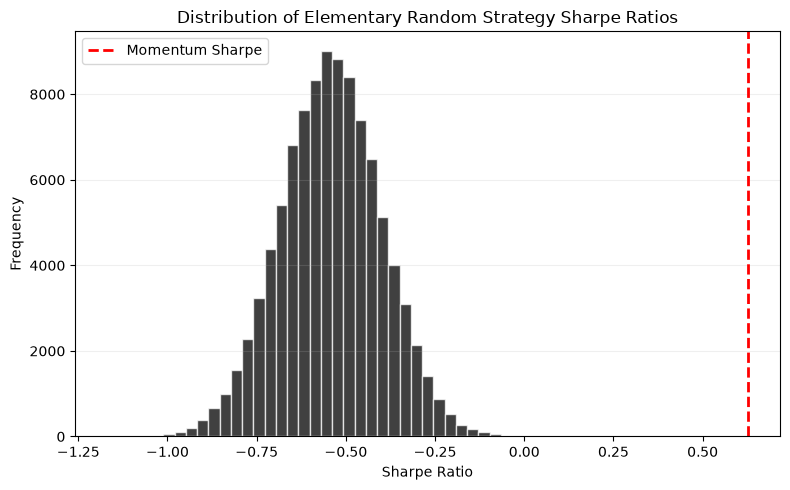

In [11]:
random_summary = summary(simulation_df, momentum_results, "elementary_random_strategy")